# Lab 4: Prototype AI features in a web app

To start, save a copy to your Drive (File, then Save a copy in Drive) and pick a GPU runtime (Runtime, then Change runtime type, then T4 GPU). This lab goes with Lecture 12 and Milestone 3. In it, you run the course's web app template in Colab and change one part of it. The outputs below are from running it on a Mac, so your answers will be a little different.

## 1. Setup

The template is a small web app. A Python server (Flask) sends each request to a model. A plain HTML and JavaScript page shows the answer. This cell gets the template from the course's GitHub repository. It also installs anything the template needs that is missing.

In [1]:
# Get the template from the course repository on GitHub and install what it needs.
# Colab already has these libraries, so the install is usually quick.
import importlib.util, os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules
if not os.path.exists("humanaiinteraction"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/chuanenlin/humanaiinteraction"], check=True)
APP_DIR = "humanaiinteraction/template"
print("Template files:", sorted(os.listdir(APP_DIR)))

needed = {"flask": "flask", "requests": "requests", "torch": "torch", "transformers": "transformers"}  # module name: pip package name
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{APP_DIR}/requirements.txt"], check=True)
print("Installed now:", missing or "nothing, all were already there")

Template files: ['.gitignore', 'LICENSE', 'README.md', 'app.py', 'model.py', 'requirements.txt', 'static']
Installed now: nothing, all were already there


## 2. Start the app

`start_app` starts the server in the background, so you can keep running cells while it runs. It waits until the page answers before it returns. `stop_app` stops the server.

In [2]:
import time
import requests

PORT = 8000
URL = f"http://127.0.0.1:{PORT}"
app = None  # the app's process while it runs


def start_app(backend="local"):
    """Start the app in the background and wait until the page answers. If it is already running, restart it."""
    global app
    stop_app()
    env = dict(os.environ, PORT=str(PORT), MODEL_BACKEND=backend, PYTHONUNBUFFERED="1")
    server_log = open(f"{APP_DIR}/server.log", "w")  # everything the app prints, including errors
    app = subprocess.Popen([sys.executable, "app.py"], cwd=APP_DIR, env=env, stdout=server_log, stderr=subprocess.STDOUT)
    for _ in range(60):
        if app.poll() is not None:
            raise RuntimeError("The app stopped. It printed:\n" + open(f"{APP_DIR}/server.log").read())
        try:
            requests.get(URL, timeout=2)
            print(f"The app is running at {URL} (MODEL_BACKEND={backend}).")
            return
        except requests.RequestException:
            time.sleep(1)
    raise RuntimeError("The app did not answer within a minute. See server.log in the template folder.")


def stop_app():
    """Stop the app if it is running."""
    global app
    if app is not None and app.poll() is None:
        app.terminate()
        app.wait()
    app = None

The model loads when the app gets its first request. The first time, the app also downloads the model (Qwen2.5-0.5B-Instruct, about 1 GB), so this cell can take a minute or two. If the model cannot load, the app starts again with a pretend model instead (`MODEL_BACKEND=fake`). The pretend model only repeats your request back, but it answers right away, so you can still work on the page.

In [3]:
# To try a larger model, uncomment the next line before you start the app.
# os.environ["MODEL_ID"] = "Qwen/Qwen2.5-1.5B-Instruct"
BACKEND = "local"
start_app(BACKEND)

try:
    first = requests.post(f"{URL}/api/generate", json={"prompt": "Say hello in five words.", "session": "notebook"}, timeout=900)
    first.raise_for_status()
    print("The model answered:", first.json()["text"])
except requests.RequestException:
    print("The model did not load (server.log in the template folder says why), so the app now uses the pretend model.")
    BACKEND = "fake"
    start_app(BACKEND)

The app is running at http://127.0.0.1:8000 (MODEL_BACKEND=local).


The model answered: Hello, how can I help you?


## 3. Open the page

In Colab, the next cell shows the page inside the notebook. You can type a request into the page and press Ask. If the page stays blank, you can open it in its own browser tab with the line in the comment. Outside Colab, the cell prints the address to open in your browser.

In [4]:
if IN_COLAB:
    # Colab shows the page through its own web address, since 127.0.0.1 here is the Colab computer.
    from google.colab import output
    output.serve_kernel_port_as_iframe(PORT, height=800)
    # To open the page in its own browser tab instead, run this line:
    # output.serve_kernel_port_as_window(PORT)
else:
    print(f"Open {URL} in your browser.")

Open http://127.0.0.1:8000 in your browser.


This is what the page looks like after one request:

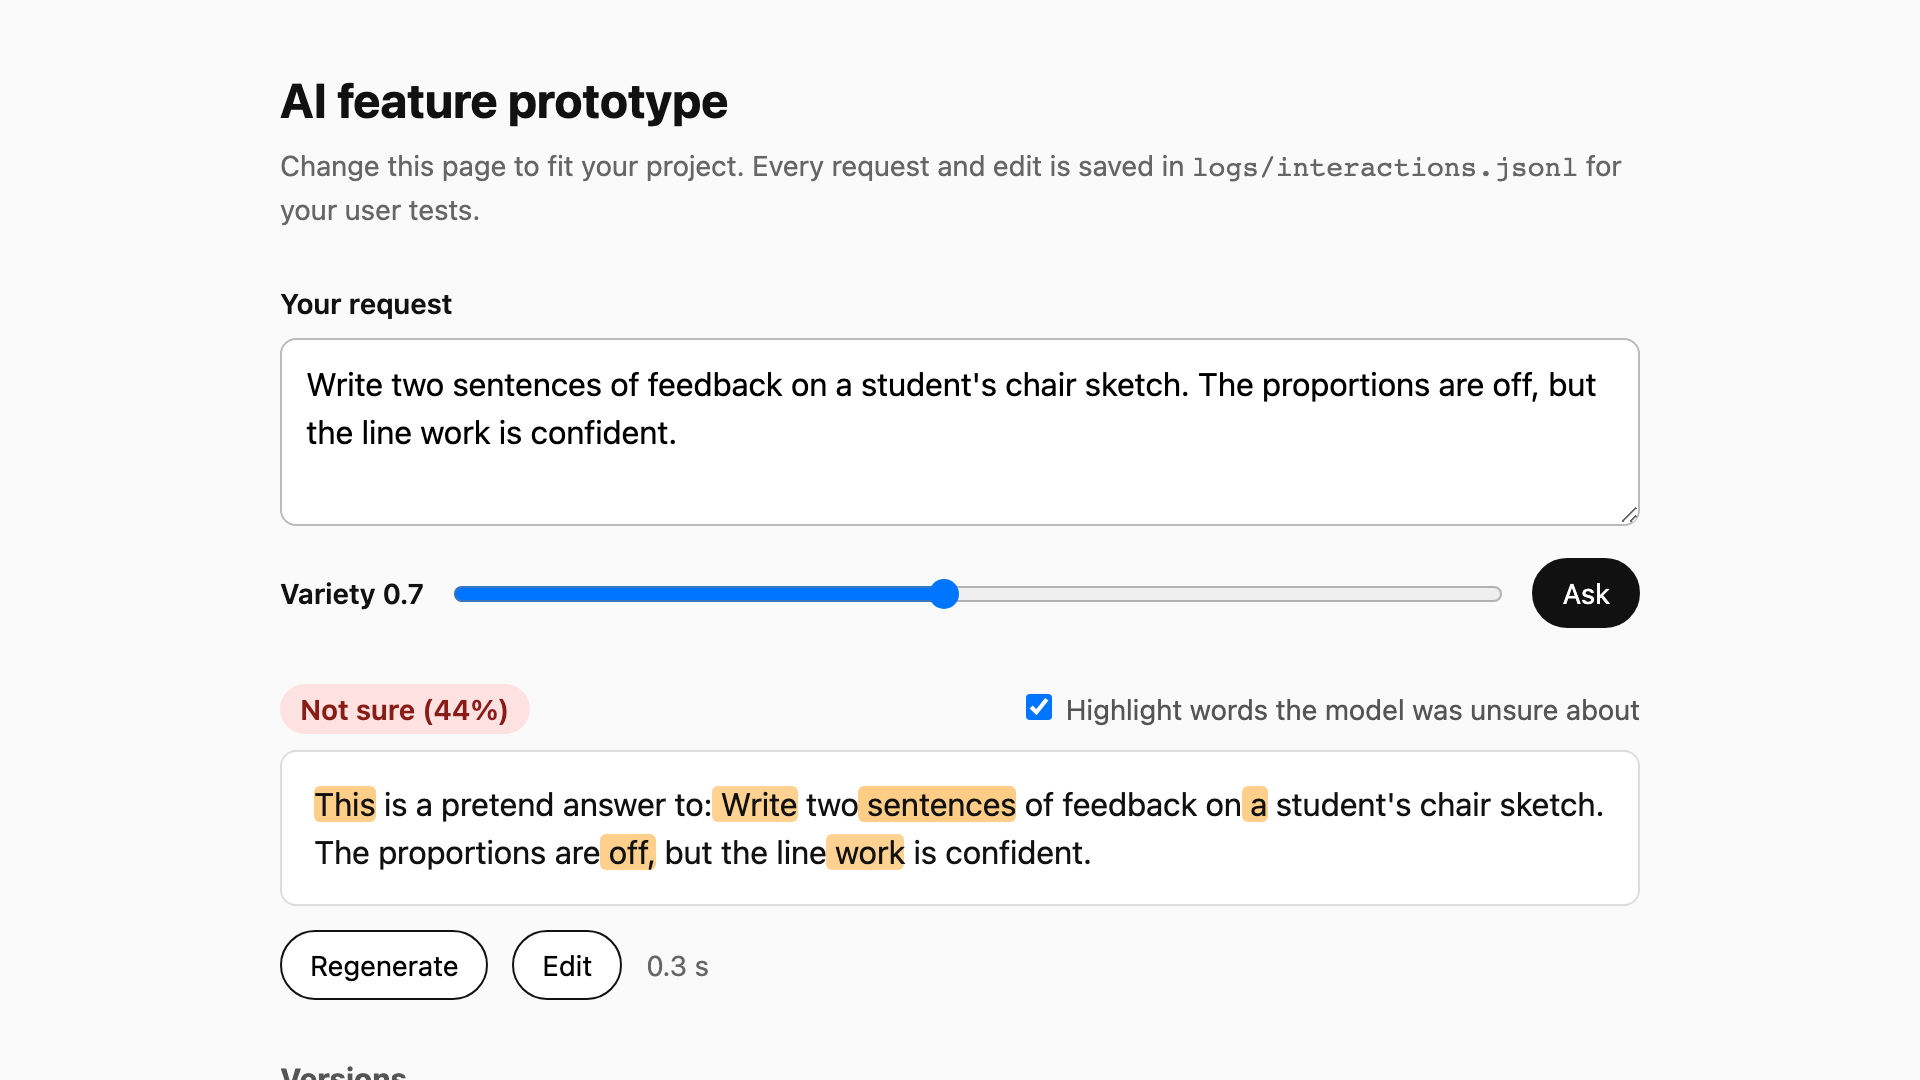

The label above the answer says how sure the model was. The colored words are the ones it gave a low probability. Below the answer, you can regenerate it, edit it, or go back to an earlier version. This screenshot was taken with the pretend model, so its answer only repeats the request. Its probabilities are random too.

## 4. Ask from code

The page sends each request to the app at `/api/generate`. You can send requests there from Python too. For example, you can try ten wordings of a request without typing each one into the page. Each answer comes back with a confidence and a probability for every token. `ask` prints the answer, the confidence, and the five words the model was least sure about.

In [5]:
def ask(prompt, temperature=0.7):
    """Send a request to the app the same way the page does, and print what comes back."""
    reply = requests.post(f"{URL}/api/generate", json={"prompt": prompt, "temperature": temperature, "session": "notebook"},
                          timeout=300).json()
    if "error" in reply:
        print(reply["error"])
        return reply
    print(reply["text"])
    print()
    if reply["confidence"] is None:
        print("This model does not report confidence.")
        return reply
    print(f"Confidence: {reply['confidence']:.0%}")
    words = [t for t in reply["tokens"] if any(ch.isalnum() for ch in t["text"])]  # skip spaces and punctuation
    least_sure = sorted(words, key=lambda t: t["prob"])[:5]
    print("Least sure about:", ", ".join(f"{t['text'].strip()} ({t['prob']:.1%})" for t in least_sure))
    return reply


REQUEST = "Give feedback on my chair sketch. The proportions are off, but the line work is confident."
reply = ask(REQUEST)

Your chair sketch has some room for improvement in terms of proportion and line work. While you've got good representation of your design elements, there's still room to refine the overall perspective and balance. Consider focusing on refining the proportions to make the chair look more balanced and visually appealing. Additionally, enhancing the control and precision with lines can further enhance its presentation quality. Overall, you're doing well towards achieving a professional drawing, so continue working on these aspects to truly elevate your piece!

Confidence: 21%
Least sure about: control (0.2%), truly (0.2%), towards (0.3%), quality (0.4%), perspective (0.7%)


## 5. Change the feature

This changes one thing in `model.py`, the instruction the model gets before every request. The new instruction asks for two lines, one that starts with "Works:" and one that starts with "Change:". You can write your own `INSTRUCTION` and run the cell again.

In [6]:
import re

# The instruction the model gets before every request. In the template it is "You are a helpful assistant. Keep answers short."
INSTRUCTION = "You are a design teacher. Reply with exactly two lines. Start the first with 'Works:' and the second with 'Change:'."

path = f"{APP_DIR}/model.py"
code = open(path).read()
code = re.sub(r"^SYSTEM_PROMPT = .*$", lambda m: f"SYSTEM_PROMPT = {INSTRUCTION!r}", code, count=1, flags=re.M)
open(path, "w").write(code)
print([line for line in code.splitlines() if line.startswith("SYSTEM_PROMPT")][0])

SYSTEM_PROMPT = "You are a design teacher. Reply with exactly two lines. Start the first with 'Works:' and the second with 'Change:'."


The app reads `model.py` only when it starts, so this cell restarts it and asks the same request again. A model this small does not always follow the instruction, so you may need to run the cell a few times. You build your own feature the same way. In Colab, you can open any file of the template from the Files panel on the left. After you change a file, run this cell again to restart the app. To see a change to the page, run the cell in part 3 again. For example, `static/app.js` colors the words with a probability below `UNSURE_BELOW` (0.3), and you can try another number there.

In [7]:
start_app(BACKEND)  # the app reads model.py when it starts
reply = ask(REQUEST)

The app is running at http://127.0.0.1:8000 (MODEL_BACKEND=local).


Works:
The proposed chair has a slight misalignment in its geometry, which slightly affects its balance; however, it maintains good proportionality.
Change:
Consider adjusting the chair's alignment to ensure it works better together in terms of stability and comfort.

Confidence: 16%
Least sure about: proposed (0.1%), works (0.4%), slightly (0.6%), geometry (0.9%), good (0.9%)


## 6. Read the log

The app writes one line to `logs/interactions.jsonl` for every event. An event is a request, a regeneration, an edit, or going back to an earlier version. This cell loads the log with pandas. You can use it as data in your Milestone 3 tests. For example, the second table counts each kind of event for each page load. Each page load gets its own session id. The requests from this notebook have the session `notebook`. The run below only sent requests from code, so its log has no regenerations or edits.

In [8]:
import pandas as pd
from IPython.display import display

LOG_FILE = f"{APP_DIR}/logs/interactions.jsonl"
log = pd.read_json(LOG_FILE, lines=True)
pd.set_option("display.max_colwidth", 60)
display(log[["time", "session", "event"] + [c for c in log.columns if c not in ("time", "session", "event")]])

# How many times each session did each thing
display(log.groupby(["session", "event"]).size().unstack(fill_value=0))

,time,session,event,id,prompt,temperature,text,confidence
0,2026-11-14 03:19:49,notebook,generate,da61f020,Say hello in five words.,0.7,"Hello, how can I help you?",0.6169
1,2026-11-14 03:19:49,notebook,generate,3a0e93ca,Give feedback on my chair sketch. The proportions are of...,0.7,Your chair sketch has some room for improvement in terms...,0.2145
2,2026-11-14 03:19:54,notebook,generate,0e3fa87d,Give feedback on my chair sketch. The proportions are of...,0.7,Works:\nThe proposed chair has a slight misalignment in ...,0.1563


event,generate
session,
notebook,3


## 7. Save your work and stop the app

Colab deletes your changes and the log when the runtime ends. This cell saves the template folder, with your changes and the log, as a zip file to download. Then it stops the app. You can also run the saved app on your own computer with the steps in its `README.md`.

In [9]:
import shutil

# Save the template folder (your changes and the log) as a zip file.
zip_path = shutil.make_archive("lab-4-app", "zip", APP_DIR)
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)
else:
    print("Saved", os.path.basename(zip_path))

stop_app()
print("Stopped the app.")

Saved lab-4-app.zip


Stopped the app.
